# 02 — Classificação: Fashion-MNIST

**O que este notebook mostra**
1. MLP com **sigmoid + BCE** (uma sigmoid por classe, alvo one-hot) × **softmax + entropia cruzada**.
2. Curvas de custo e acurácia (treino e validação) e histogramas.
3. Comparativos rápidos: **SGD × Adam** e **He × Xavier**.
4. Exportar → importar → inferir com pixels brutos (0–255).
5. Tabela final e matriz de confusão no conjunto de **teste** (usado uma única vez).

> **BCE com 10 classes?** BCE é uma loss binária. Com one-hot + uma sigmoid por saída, cada saída
> responde sozinha "é da classe k?": são 10 problemas binários em paralelo. As 10 probabilidades não
> somam 1 (diferente da softmax); a classe prevista é a de maior probabilidade.

In [1]:
import numpy as np

from rede import MLP
from treino import treinar, acuracia
from exportacao import salvar_modelo, carregar_modelo
from dados import carregar_fashion_mnist
import graficos as g
import graficos_gradientes as gg

MODO_RAPIDO = True   # True: 8 mil imagens e poucas épocas (< 60 s)
g.configurar_estilo()

In [2]:
dados = carregar_fashion_mnist(modo_rapido=MODO_RAPIDO)
print("treino:", dados["X_treino"].shape, " validação:", dados["X_val"].shape, " teste:", dados["X_teste"].shape)
print("classes:", dados["nomes_classes"])

treino: (5600, 784)  validação: (1200, 784)  teste: (1200, 784)
classes: ['Camiseta', 'Calça', 'Pulôver', 'Vestido', 'Casaco', 'Sandália', 'Camisa', 'Tênis', 'Bolsa', 'Bota']


## 1. Sigmoid + BCE × Softmax + Entropia Cruzada

A softmax e a entropia cruzada estão em `rede.py` e foram feitas **só compondo** `exp`, `sum`, `/` e `log`
(com o truque de subtrair o máximo da linha para não estourar o `exp`). Nenhuma derivada foi escrita.

In [3]:
EPOCAS = 10 if MODO_RAPIDO else 40

config_base = {
    "n_entrada": 784,
    "camadas_ocultas": [128, 64],
    "n_saida": 10,
    "ativacao_oculta": "relu",
    "inicializacao": "he",
    "seed": 42,
}
treino_base = {"metrica": "acuracia", "otimizador": "adam", "taxa_aprendizado": 1e-3,
               "epocas": EPOCAS, "tamanho_lote": 64, "coletar_a_cada": 3}

rede_bce = MLP(dict(config_base, ativacao_saida="sigmoid"))
hist_bce = treinar(rede_bce, dados, dict(treino_base, perda="bce", verbose=False))

rede_ce = MLP(dict(config_base, ativacao_saida="softmax"))
hist_ce = treinar(rede_ce, dados, dict(treino_base, perda="entropia_cruzada", paciencia=4))

época   1 | perda treino 0.6114 val 0.6469 | acuracia treino 0.7930 val 0.7700


época   2 | perda treino 0.5002 val 0.5763 | acuracia treino 0.8314 val 0.8008


época   3 | perda treino 0.4315 val 0.5247 | acuracia treino 0.8532 val 0.8133


época   4 | perda treino 0.4096 val 0.5192 | acuracia treino 0.8550 val 0.8108


época   5 | perda treino 0.4206 val 0.5075 | acuracia treino 0.8455 val 0.8100


época   6 | perda treino 0.3524 val 0.4883 | acuracia treino 0.8762 val 0.8217


época   7 | perda treino 0.3707 val 0.4860 | acuracia treino 0.8684 val 0.8275


época   8 | perda treino 0.3006 val 0.4716 | acuracia treino 0.8923 val 0.8267


época   9 | perda treino 0.3511 val 0.5586 | acuracia treino 0.8768 val 0.8067


época  10 | perda treino 0.2772 val 0.4947 | acuracia treino 0.8988 val 0.8200


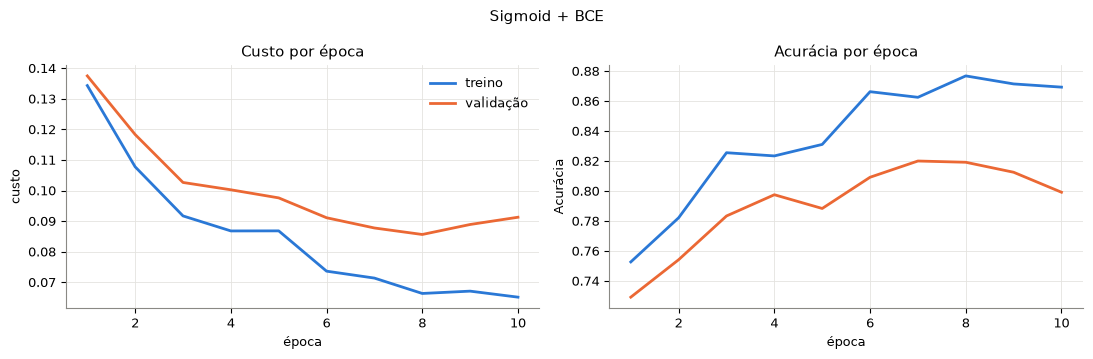

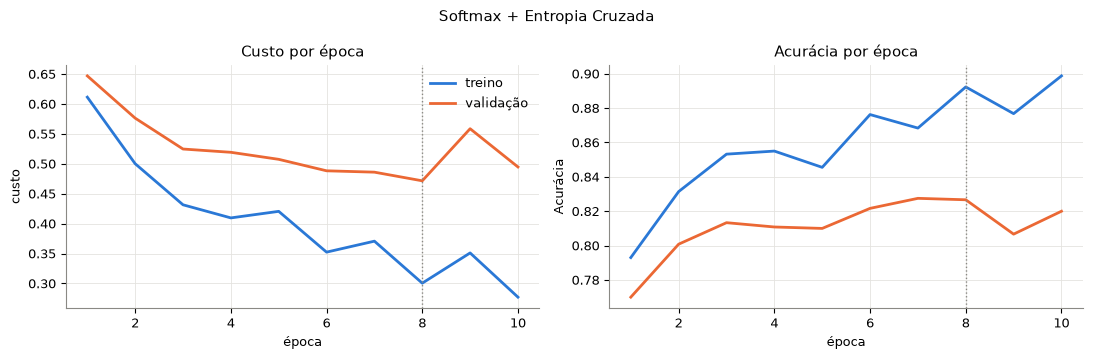

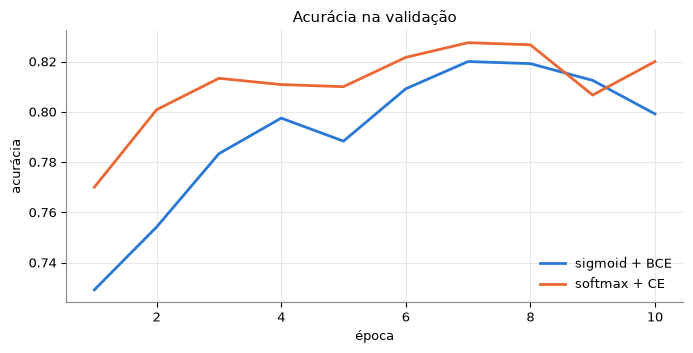

In [4]:
g.plot_curvas(hist_bce, "Sigmoid + BCE")
g.plot_curvas(hist_ce, "Softmax + Entropia Cruzada")
g.plot_comparacao({"sigmoid + BCE": hist_bce, "softmax + CE": hist_ce},
                  chave="metrica_val", titulo="Acurácia na validação", ylabel="acurácia")

## 2. Histogramas (modelo softmax + CE)

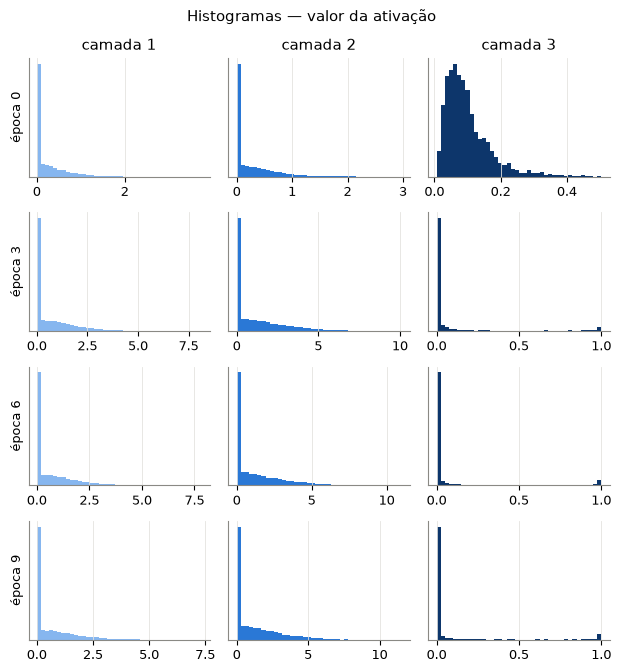

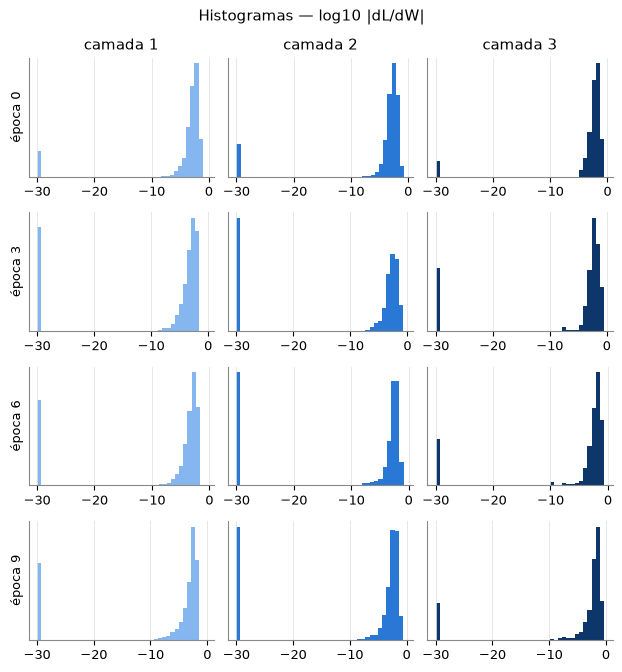

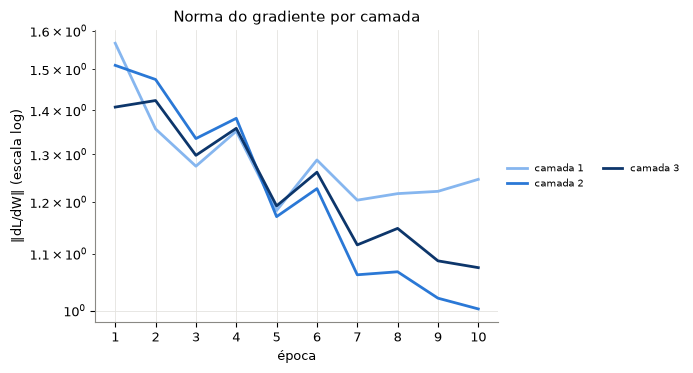

In [5]:
gg.plot_histogramas(hist_ce, "ativacoes")
gg.plot_histogramas(hist_ce, "grad_pesos")
gg.plot_norma_grad_por_camada(hist_ce)

## 3. Comparativos rápidos: SGD × Adam e He × Xavier

Mesma rede (softmax + CE), mudando só uma coisa por vez.

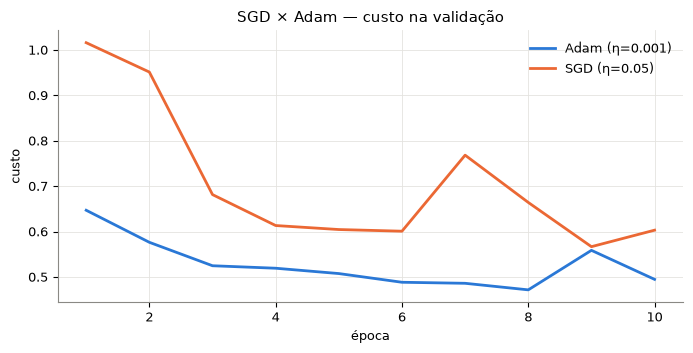

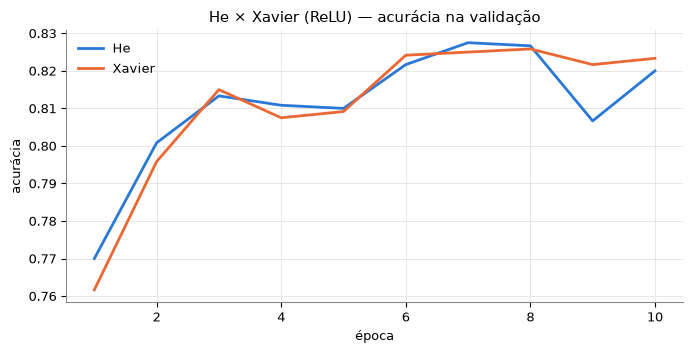

In [6]:
config_ce = dict(config_base, ativacao_saida="softmax")
treino_ce = dict(treino_base, perda="entropia_cruzada", verbose=False)

rede_sgd = MLP(config_ce)
hist_sgd = treinar(rede_sgd, dados, dict(treino_ce, otimizador="sgd", taxa_aprendizado=0.05))

rede_xavier = MLP(dict(config_ce, inicializacao="xavier"))
hist_xavier = treinar(rede_xavier, dados, treino_ce)

g.plot_comparacao({"Adam (η=0.001)": hist_ce, "SGD (η=0.05)": hist_sgd},
                  chave="perda_val", titulo="SGD × Adam — custo na validação", ylabel="custo")
g.plot_comparacao({"He": hist_ce, "Xavier": hist_xavier},
                  chave="metrica_val", titulo="He × Xavier (ReLU) — acurácia na validação", ylabel="acurácia")

## 4. Exportar → importar → inferir com pixels brutos

A divisão por 255 está registrada no arquivo (`media_x = 0`, `desvio_x = 255`), então o modelo importado
recebe a imagem crua.

In [7]:
rede_ce.padronizacao = dados["padronizacao"]
caminho = "modelos/classificacao_fashion.json"
salvar_modelo(rede_ce, caminho, nome_perda="entropia_cruzada",
              metricas={"acuracia_val": max(hist_ce["metrica_val"])})

importada = carregar_modelo(caminho)
prob_importada = importada.prever(dados["X_teste_bruto"])
print("predições idênticas após importar?", np.allclose(rede_ce.prever(dados["X_teste_bruto"]), prob_importada))

predições idênticas após importar? True


## 5. Resultado final no teste (usado uma única vez)

modelo                           acuracia
-----------------------------------------
sigmoid + BCE (Adam, He)           0.8350
softmax + CE (Adam, He)            0.8542
softmax + CE (SGD, He)             0.7817
softmax + CE (Adam, Xavier)        0.8433


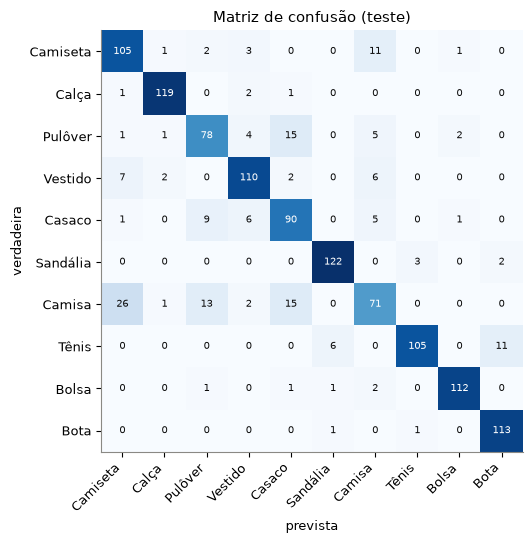

In [8]:
modelos = {"sigmoid + BCE (Adam, He)": rede_bce, "softmax + CE (Adam, He)": importada,
           "softmax + CE (SGD, He)": rede_sgd, "softmax + CE (Adam, Xavier)": rede_xavier}
resultados = {}
for nome, modelo in modelos.items():
    probabilidades = modelo.forward(dados["X_teste"]).data
    resultados[nome] = {"acuracia": acuracia(probabilidades, dados["Y_teste"])}
g.imprimir_tabela(resultados)
g.plot_matriz_confusao(prob_importada, dados["Y_teste"], dados["nomes_classes"])

## Conclusões
- As duas formulações funcionam; softmax + CE modela diretamente "uma classe entre 10" (probabilidades somam 1), enquanto sigmoid + BCE trata cada classe como um problema binário independente.
- Adam converge bem mais rápido que SGD com a mesma quantidade de épocas.
- Com ReLU, He e Xavier ficam próximos numa rede rasa; a diferença aparece em redes fundas (ver notebook 03).
- As confusões se concentram em classes parecidas (camisa × camiseta × pulôver × casaco).
- O modelo importado reproduz exatamente as predições, recebendo pixels brutos.